Set-up Colab paths


In [1]:
import time, json, hashlib, zipfile
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED, BATCH, IMG_SIZE = 42, 32, (64, 64)       # same as Model B
tf.keras.utils.set_random_seed(SEED)

ROOT       = Path("/content")
DATA_ROOT  = ROOT / "data"
SPLIT_CSV  = DATA_ROOT / "eurosat_split.csv"   # the group's shared split (uploaded below)
ZIP_PATH   = DATA_ROOT / "EuroSAT_RGB.zip"
DATASET_URL = "https://zenodo.org/records/7711810/files/EuroSAT_RGB.zip?download=1"
DATASET_MD5 = "f46e308c4d50d4bf32fedad2d3d62f3b"   # official checksum (same one Model B's notebook uses)

DATA_ROOT.mkdir(exist_ok=True)
(ROOT / "results").mkdir(exist_ok=True); (ROOT / "figures").mkdir(exist_ok=True)
print("TF", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU") or "none")

TF 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
# Upload the split CSV
from google.colab import files

if not SPLIT_CSV.exists():
    uploaded = files.upload()                       # choose eurosat_split.csv in the dialog
    name = next(iter(uploaded))
    Path(name).rename(SPLIT_CSV)

split_check = pd.read_csv(SPLIT_CSV, dtype=str)
print(split_check.columns.tolist())                 # expect ['file', 'label', 'split']
print(split_check.groupby("split").size().to_dict())   # expect train 18900 / val 4050 / test 4050

Saving eurosat_split.csv to eurosat_split.csv
['file', 'label', 'split']
{'test': 4050, 'train': 18900, 'val': 4050}


Download and extract EuroSat dataset

In [3]:
def md5_of(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

# Download once (-c resumes if the connection drops)
if not ZIP_PATH.exists():
    !wget -c -q --show-progress -O "{ZIP_PATH}" "{DATASET_URL}"

# Verify the file is complete and uncorrupted
assert md5_of(ZIP_PATH) == DATASET_MD5, "MD5 mismatch: delete the zip and re-run this cell"
print("Checksum OK")

# Extract once
EXTRACT_DIR = DATA_ROOT / "eurosat"
if not EXTRACT_DIR.exists():
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(EXTRACT_DIR)

# Find the folder that directly contains the class folders (robust to the zip's layout)
DATA_DIR = next(p.parent for p in EXTRACT_DIR.rglob("AnnualCrop") if p.is_dir())
print("Images are in:", DATA_DIR)
print(sorted(p.name for p in DATA_DIR.iterdir() if p.is_dir()))

/content/data/EuroS 100%[===================>]  90.27M  1004KB/s    in 1m 51s  
Checksum OK
Images are in: /content/data/eurosat/EuroSAT_RGB
['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


Load data

In [4]:
df = pd.read_csv(SPLIT_CSV, dtype=str)                       # columns: file, label, split
df["path"] = [str(DATA_DIR / l / f) for l, f in zip(df.label, df.file)]
assert all(Path(p).exists() for p in df.path.head(50)), "Image paths don't match: check DATA_DIR"

CLASS_NAMES = sorted(df.label.unique())
df["y"] = df.label.map({c: i for i, c in enumerate(CLASS_NAMES)})

def load_image(path, label):
    img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    img = tf.ensure_shape(img, IMG_SIZE + (3,))
    return tf.image.convert_image_dtype(img, tf.float32), label   # pixels scaled to [0, 1]

def make_ds(split_name, shuffle):
    d = df[df.split == split_name].sort_values(["label", "file"])
    ds = tf.data.Dataset.from_tensor_slices(
        (d.path.to_numpy(dtype=str), d.y.to_numpy(dtype=np.int32)))
    if shuffle:
        ds = ds.shuffle(len(d), seed=SEED)
    return ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds, val_ds, test_ds = make_ds("train", True), make_ds("val", False), make_ds("test", False)
print(df.groupby("split").size().to_dict())    # expect 18900 / 4050 / 4050

{'test': 4050, 'train': 18900, 'val': 4050}


Build MobileNetV2 with a new 10-class head

In [5]:
def build_mobilenetv2():
    base = tf.keras.applications.MobileNetV2(
        input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet")
    base.trainable = False                          # phase 1: keep the pretrained part frozen

    inputs = layers.Input(shape=IMG_SIZE + (3,))
    x = layers.Rescaling(2.0, offset=-1.0)(inputs)  # [0,1] -> [-1,1], what MobileNetV2 expects
    x = base(x, training=False)                     # run the backbone in inference mode
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(len(CLASS_NAMES), activation="softmax")(x)   # the new head
    return models.Model(inputs, outputs, name="MobileNetV2"), base

model, base = build_mobilenetv2()
model.summary()

/tmp/ipykernel_648/4159959230.py:2: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = tf.keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 2, 2, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

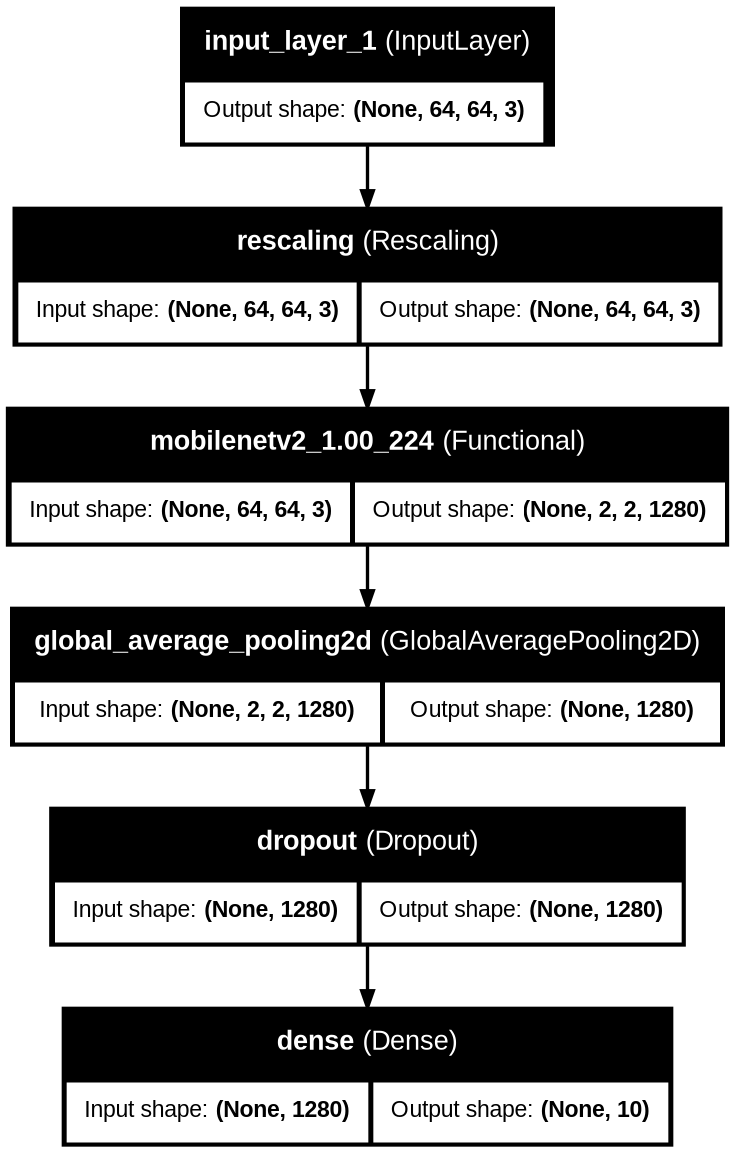

In [8]:
# plot the model architecture
tf.keras.utils.plot_model(model, to_file="figures/mobilenetv2_top.png",
                          show_shapes=True, show_layer_names=True, dpi=120)

Train in two phases

In [6]:
class EpochTimer(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None): self.times = []
    def on_epoch_begin(self, epoch, logs=None): self.t0 = time.perf_counter()
    def on_epoch_end(self, epoch, logs=None): self.times.append(time.perf_counter() - self.t0)

EPOCHS_HEAD, EPOCHS_FT = 5, 15                      # 20 epochs in total, like Model B
LOSS = "sparse_categorical_crossentropy"
BEST_PATH = "results/mobilenetv2_best.keras"

# Phase 1: train only the new head (backbone frozen)
model.compile(tf.keras.optimizers.Adam(1e-3), loss=LOSS, metrics=["accuracy"])
h1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD, verbose=2)

# Phase 2: unfreeze everything and fine-tune with a 10x smaller learning rate
base.trainable = True
timer = EpochTimer()
ckpt = tf.keras.callbacks.ModelCheckpoint(BEST_PATH, monitor="val_loss",
                                          mode="min", save_best_only=True)
model.compile(tf.keras.optimizers.Adam(1e-4), loss=LOSS, metrics=["accuracy"])
h2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FT,
               callbacks=[ckpt, timer], verbose=2)

model = tf.keras.models.load_model(BEST_PATH)       # go back to the best-validation weights
best_epoch = EPOCHS_HEAD + int(np.argmin(h2.history["val_loss"])) + 1
time_per_epoch = float(np.mean(timer.times[1:]))    # first epoch excluded, like Model B
print(f"Best epoch {best_epoch} | {time_per_epoch:.1f} s per fine-tuning epoch")

Epoch 1/5
591/591 - 30s - 51ms/step - accuracy: 0.7677 - loss: 0.7180 - val_accuracy: 0.8449 - val_loss: 0.4724
Epoch 2/5
591/591 - 6s - 9ms/step - accuracy: 0.8579 - loss: 0.4380 - val_accuracy: 0.8583 - val_loss: 0.4160
Epoch 3/5
591/591 - 6s - 10ms/step - accuracy: 0.8743 - loss: 0.3844 - val_accuracy: 0.8642 - val_loss: 0.4071
Epoch 4/5
591/591 - 10s - 17ms/step - accuracy: 0.8830 - loss: 0.3532 - val_accuracy: 0.8627 - val_loss: 0.4167
Epoch 5/5
591/591 - 6s - 10ms/step - accuracy: 0.8882 - loss: 0.3361 - val_accuracy: 0.8635 - val_loss: 0.4144
Epoch 1/15
591/591 - 100s - 170ms/step - accuracy: 0.7783 - loss: 0.8281 - val_accuracy: 0.7057 - val_loss: 1.5745
Epoch 2/15
591/591 - 15s - 25ms/step - accuracy: 0.8860 - loss: 0.3552 - val_accuracy: 0.8630 - val_loss: 0.6404
Epoch 3/15
591/591 - 12s - 20ms/step - accuracy: 0.9183 - loss: 0.2580 - val_accuracy: 0.9047 - val_loss: 0.3836
Epoch 4/15
591/591 - 12s - 21ms/step - accuracy: 0.9372 - loss: 0.1946 - val_accuracy: 0.9193 - val_los

Training Curves

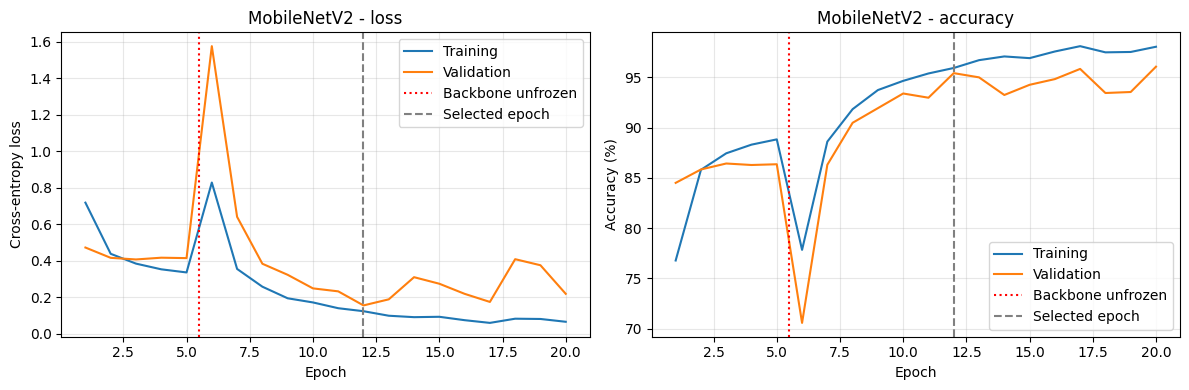

In [7]:
hist = {k: h1.history[k] + h2.history[k] for k in ["loss", "val_loss", "accuracy", "val_accuracy"]}
ep = np.arange(1, len(hist["loss"]) + 1)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ep, hist["loss"], label="Training");     ax[0].plot(ep, hist["val_loss"], label="Validation")
ax[0].set(title="MobileNetV2 - loss", xlabel="Epoch", ylabel="Cross-entropy loss")
ax[1].plot(ep, np.array(hist["accuracy"]) * 100, label="Training")
ax[1].plot(ep, np.array(hist["val_accuracy"]) * 100, label="Validation")
ax[1].set(title="MobileNetV2 - accuracy", xlabel="Epoch", ylabel="Accuracy (%)")
for a in ax:
    a.axvline(EPOCHS_HEAD + 0.5, color="red", ls=":", label="Backbone unfrozen")
    a.axvline(best_epoch, color="gray", ls="--", label="Selected epoch")
    a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.savefig("figures/mobilenetv2_curves.png", dpi=150); plt.show()

Test Evaluation

Test accuracy: 96.10%

                      precision    recall  f1-score   support

          AnnualCrop     0.9680    0.9422    0.9550       450
              Forest     0.9593    0.9956    0.9771       450
HerbaceousVegetation     0.9464    0.9422    0.9443       450
             Highway     0.9721    0.9280    0.9495       375
          Industrial     0.9786    0.9733    0.9759       375
             Pasture     0.9656    0.9367    0.9509       300
       PermanentCrop     0.9297    0.9173    0.9235       375
         Residential     0.9780    0.9867    0.9823       450
               River     0.9337    0.9760    0.9544       375
             SeaLake     0.9760    0.9956    0.9857       450

            accuracy                         0.9610      4050
           macro avg     0.9607    0.9594    0.9599      4050
        weighted avg     0.9611    0.9610    0.9609      4050



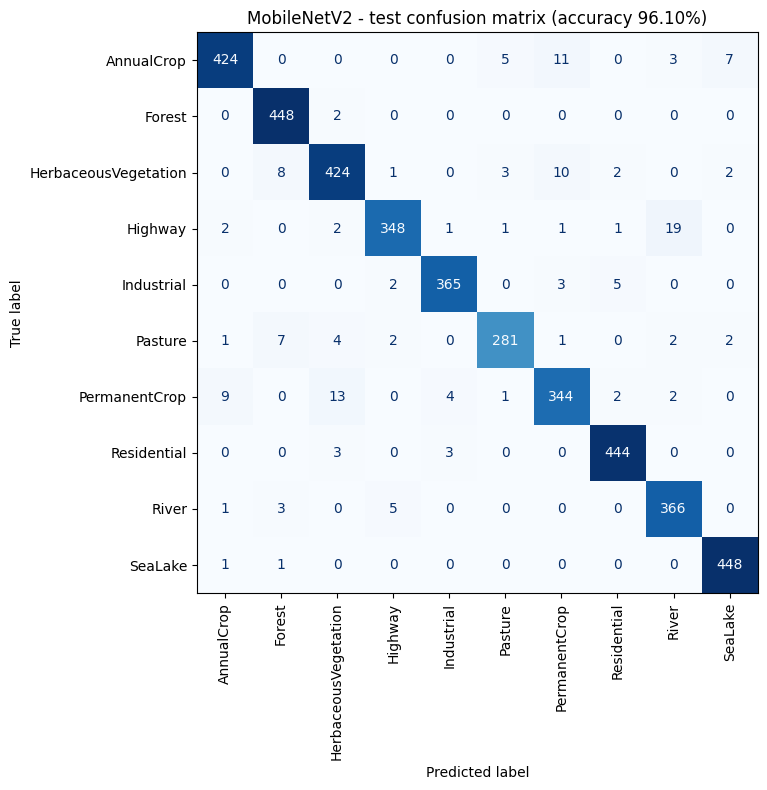

In [9]:
y_true = np.concatenate([y.numpy() for _, y in test_ds])    # test_ds is not shuffled
y_pred = np.argmax(model.predict(test_ds, verbose=0), axis=1)
test_acc = float((y_true == y_pred).mean())
print(f"Test accuracy: {test_acc:.2%}\n")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
    ax=ax, cmap="Blues", xticks_rotation=90, values_format="d", colorbar=False)
ax.set_title(f"MobileNetV2 - test confusion matrix (accuracy {test_acc:.2%})")
plt.tight_layout(); plt.savefig("figures/mobilenetv2_confusion.png", dpi=150); plt.show()

In [10]:
# Save an "uncompiled" copy (no optimizer state), as Model B did, so file sizes are comparable
deploy, _ = build_mobilenetv2()
deploy.set_weights(model.get_weights())
deploy.save("results/mobilenetv2.keras")
size_mb = Path("results/mobilenetv2.keras").stat().st_size / 1024**2

total = deploy.count_params()
trainable = int(sum(np.prod(w.shape) for w in deploy.trainable_weights))

def count_macs(m):                                  # conv + dense only, BatchNorm excluded (Model B's rule)
    total = 0
    for layer in m.layers:
        if isinstance(layer, tf.keras.Model):
            total += count_macs(layer)
        elif isinstance(layer, layers.DepthwiseConv2D):
            h, w, c = layer.output.shape[1:]
            total += h * w * layer.kernel_size[0] * layer.kernel_size[1] * c
        elif isinstance(layer, layers.Conv2D):
            h, w, c_out = layer.output.shape[1:]
            total += h * w * layer.kernel_size[0] * layer.kernel_size[1] * layer.input.shape[-1] * c_out
        elif isinstance(layer, layers.Dense):
            total += layer.input.shape[-1] * layer.units
    return total
macs = count_macs(deploy)

print(f"Total params     : {total:,}")
print(f"Trainable params : {trainable:,}")
print(f"Model size       : {size_mb:.2f} MB")
print(f"MACs per image   : {macs:,} (~{macs/1e6:.1f} M)")
print(f"Time per epoch   : {time_per_epoch:.1f} s")
print(f"Test accuracy    : {test_acc:.2%}")

json.dump({"model": "MobileNetV2", "total_params": total, "trainable_params": trainable,
           "size_mb": size_mb, "macs": int(macs), "time_per_epoch_s": time_per_epoch,
           "test_accuracy": test_acc, "best_epoch": best_epoch,
           "confusion_matrix": cm.tolist()},
          open("results/mobilenetv2.json", "w"), indent=2)

/tmp/ipykernel_648/4159959230.py:2: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = tf.keras.applications.MobileNetV2(


Total params     : 2,270,794
Trainable params : 12,810
Model size       : 9.22 MB
MACs per image   : 24,461,312 (~24.5 M)
Time per epoch   : 13.6 s
Test accuracy    : 96.10%
